# 03 · Identificación de la mancha y datos procesados (S4)

**Algoritmo** (copiado de `sun_spots_pulsation/src/segmentation.py`, `select_spot_cluster`). Los nombres en `MAYÚSCULAS` son los parámetros de la celda siguiente:
1. Huella oscura: $I_c/I_{qs} <$ `PENUMBRA_FRAC`, umbra y penumbra juntas.
2. `ndimage.label` separa las manchas (`CONNECTIVITY` = 2 incluye vecinos diagonales) y descarta las de menos de `MIN_SPOT_PX` px.
3. Se sigue **una sola** mancha. En el primer frame se elige por `seed`:
   - `largest`: la de mayor área, como el `cluster_mode='largest'` de tu proyecto.
   - `leader`: la más al oeste entre las que tienen al menos `LEADER_MIN_FRACTION` del área de la mayor (12574).
   - `central`: la más cercana al centro del cutout.
   - `(x, y)`: la más cercana a ese píxel del primer frame, para elegir a mano (se lee de la vista previa).

   En los frames siguientes se sigue a la misma mancha por máximo solapamiento con la selección anterior.
4. Umbra = $I_c/I_{qs}<$ `UMBRA_FRAC` dentro de esa mancha; penumbra = el resto de la mancha.

Después la máscara se reproyecta a la malla **CEA** de SHARP (vecino más cercano). Ahí el vector $\mathbf B$ ya está en coordenadas locales $(B_x, B_y, B_z)$ y cada píxel tiene la misma área.

**Salida** en `data/processed/<id>/`, todo FITS 2D que se abre con `sunpy.map.Map`:

```
hpc/{continuum, magnetogram, dopplergram, mu, mask}/...
cea/{Bx, By, Bz, conf_disambig, continuum, mask}/...
frames_metrics.csv
```

Además se generan `data/processed/muestra_index.csv` (una fila por mancha) y `data/processed/sumary.html`.

## 0. Parámetros del tracker

Cambia aquí y corre el notebook de nuevo; la celda siguiente los copia a `src/config.py` en memoria (el archivo no cambia). Para revisar solo algunas manchas usa `ONLY`, y mira la vista previa (sección 1) antes de correr el análisis completo, que reescribe `data/processed/<id>/`.

In [1]:
# --- Detección y seguimiento -------------------------------------------------
UMBRA_FRAC = 0.5            # umbra: Ic/Iqs < UMBRA_FRAC
PENUMBRA_FRAC = 0.9         # mancha (umbra + penumbra): Ic/Iqs < PENUMBRA_FRAC
MIN_SPOT_PX = 50            # componentes más chicas (px HPC) se descartan
CONNECTIVITY = 2            # 1: vecinos en cruz; 2: también diagonales
LEADER_MIN_FRACTION = 0.3   # seed='leader': candidatas >= esta fracción del área de la mayor
SEED_OVERRIDE = {           # 'largest' | 'leader' | 'central' | (x, y) en px del primer frame
    # 'L11536_20120731': (305, 90),   # el (x, y) se lee de la tabla/figura de la sección 1
    'L11117_20101028': (225,270),
    'L11117_20101027': (250,300),
    'L11536_20120731': (320,80)
    
}

# --- Campo magnético ----------------------------------------------------------
CONF_DISAMBIG_MIN = 60      # píxeles SHARP con conf_disambig >= este valor
MAX_FIELD_SIGMA_PX = 2.0    # σ de la gaussiana para el máximo suavizado (px CEA)
TIME_SMOOTH_FRAMES = 5      # ventana de la mediana móvil temporal (frames de 12 min)

# --- Qué manchas ----------------------------------------------------------------
ONLY = None                 # None = todas; o p.ej. ['L11117_20101027', 'L11536_20120731']
PREVIEW = True              # sección 1: candidatas numeradas antes de escribir nada
RUN_ANALYSIS = True         # sección 2: análisis completo (escribe data/processed)

In [2]:
import pathlib, sys, warnings
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 200)

from src import config, analysis, report

for name in ('UMBRA_FRAC', 'PENUMBRA_FRAC', 'MIN_SPOT_PX', 'CONNECTIVITY', 'LEADER_MIN_FRACTION',
             'SEED_OVERRIDE', 'CONF_DISAMBIG_MIN', 'MAX_FIELD_SIGMA_PX', 'TIME_SMOOTH_FRAMES'):
    setattr(config, name, globals()[name])

SPOTS = [s for s in config.all_spots() if ONLY is None or s['id'] in ONLY]
print('manchas:', [s['id'] for s in SPOTS])

manchas: ['L11106_20100916', 'L11117_20101027', 'L11117_20101028', 'L11363_20111206', 'L11536_20120731', 'C12526', 'C12574', 'C12600', 'C12664', 'C12670']


## 1. Vista previa de la detección

Para cada mancha se dibujan el **primer frame** (donde `seed` elige la mancha) y el **central**. Cada candidata oscura lleva un número y su área desproyectada en Mm²; la elegida tiene borde azul (mancha) y rojo (umbra). La tabla de debajo es la del primer frame.

Si el área de Löptien se parece a la de **otra** candidata, el problema es la elección de la mancha: copia su `(x, y)` de la tabla a `SEED_OVERRIDE`. Si la mancha es la misma pero el área no cuadra, el problema son los umbrales `UMBRA_FRAC`/`PENUMBRA_FRAC`.

L11106_20100916 [seed=largest]: 111 frames, mancha de 1195 px (mediana), 0 cambio(s) de mancha en el seguimiento


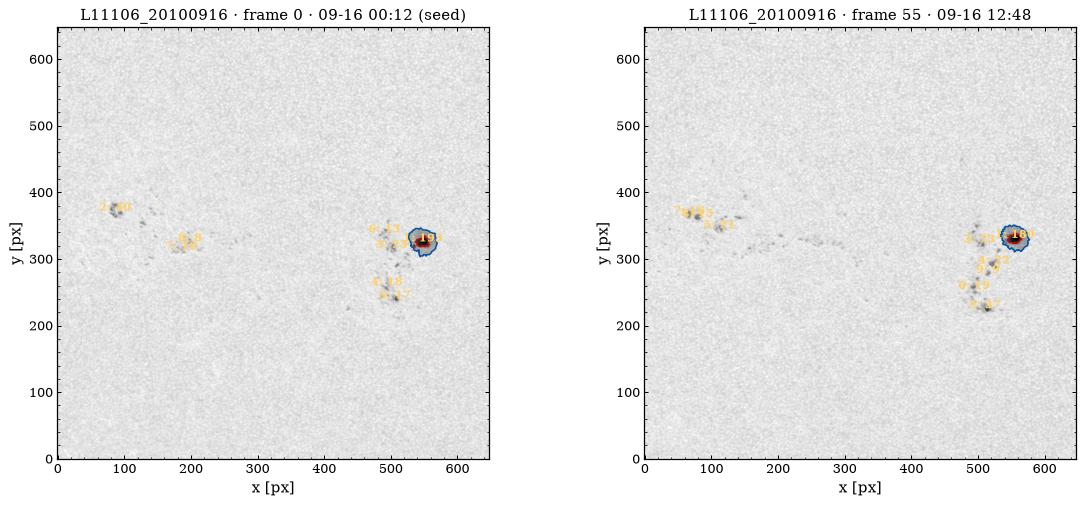

Löptien: área 195 Mm², θ = 27°


,x,y,n_px,mu,area_Mm2,umbra_Mm2
1,548.2,326.2,1250,0.9,192.8,33.0
2,86.5,372.5,235,0.8,39.5,0.0
3,501.6,316.8,149,0.9,23.2,0.0
4,494.0,260.4,112,0.9,17.8,0.0
5,506.0,240.4,109,0.8,17.4,1.4
6,490.4,339.8,87,0.9,13.5,0.0
7,185.8,314.2,62,0.8,10.3,0.0
8,198.7,326.3,51,0.8,8.4,0.0


L11117_20101027 [seed=(250, 300)]: 114 frames, mancha de 1572 px (mediana), 0 cambio(s) de mancha en el seguimiento


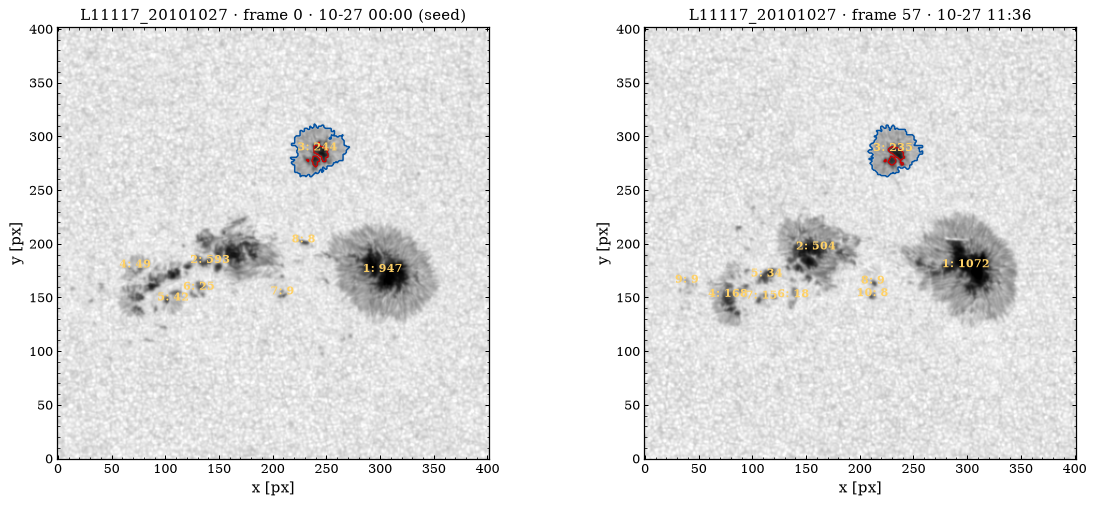

Löptien: área 522 Mm², θ = 25°


,x,y,n_px,mu,area_Mm2,umbra_Mm2
1,302.4,173.8,6577,0.9,947.1,154.1
2,141.9,182.2,4214,0.9,593.1,63.8
3,241.7,286.9,1677,0.9,244.0,25.2
4,72.0,177.9,353,0.9,49.2,0.0
5,107.5,147.2,300,0.9,41.8,0.3
6,131.4,157.2,179,0.9,25.1,0.1
7,209.1,152.9,66,0.9,9.3,0.0
8,228.9,201.2,55,0.9,7.9,0.4


L11117_20101028 [seed=(225, 270)]: 102 frames, mancha de 1406 px (mediana), 0 cambio(s) de mancha en el seguimiento


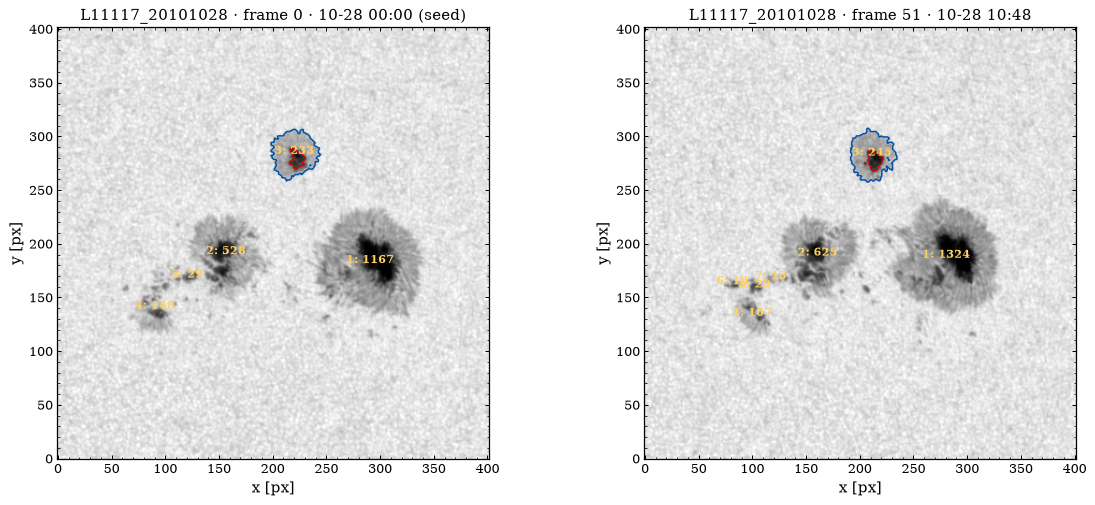

Löptien: área 223 Mm², θ = 35°


,x,y,n_px,mu,area_Mm2,umbra_Mm2
1,290.8,182.1,7309,0.8,1167.3,170.1
2,156.6,190.4,3450,0.9,527.9,62.6
3,220.2,283.8,1459,0.8,232.6,26.6
4,90.5,139.6,993,0.9,147.8,5.1
5,120.6,168.6,194,0.9,29.3,0.5


L11363_20111206 [seed=largest]: 107 frames, mancha de 7923 px (mediana), 0 cambio(s) de mancha en el seguimiento


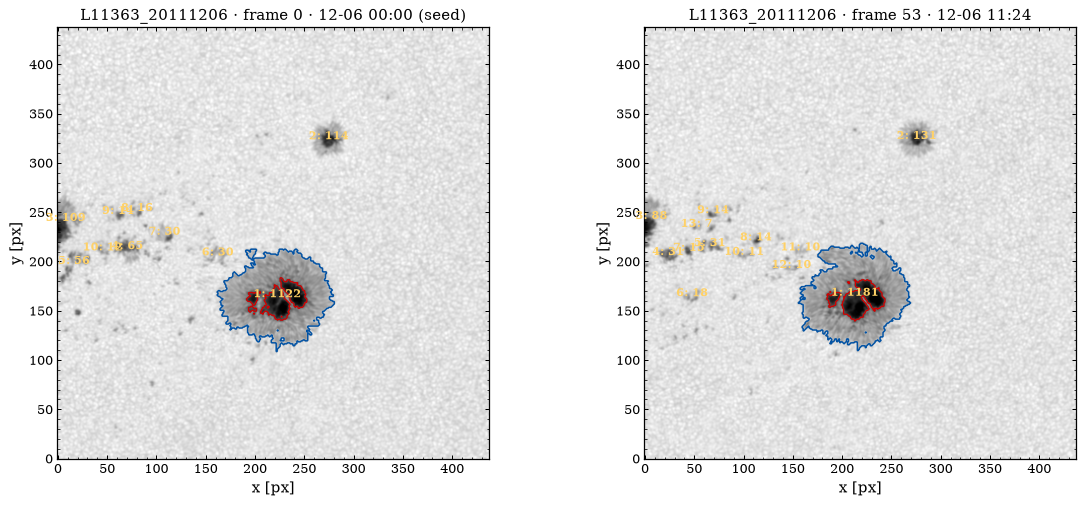

Löptien: área 1268 Mm², θ = 25°


,x,y,n_px,mu,area_Mm2,umbra_Mm2
1,222.7,163.8,7845,0.9,1122.2,167.1
2,274.9,324.0,823,0.9,114.3,18.5
3,8.1,241.2,785,0.9,109.0,21.2
4,70.6,212.5,463,0.9,64.8,1.7
5,16.5,197.5,401,0.9,56.2,0.0
6,162.3,206.1,215,0.9,30.3,0.0
7,108.3,227.1,214,0.9,29.9,0.1
8,80.4,251.2,113,0.9,15.7,0.0
9,61.1,248.2,104,0.9,14.4,0.0
10,45.6,211.2,84,0.9,11.8,0.0


L11536_20120731 [seed=(320, 80)]: 115 frames, mancha de 798 px (mediana), 0 cambio(s) de mancha en el seguimiento


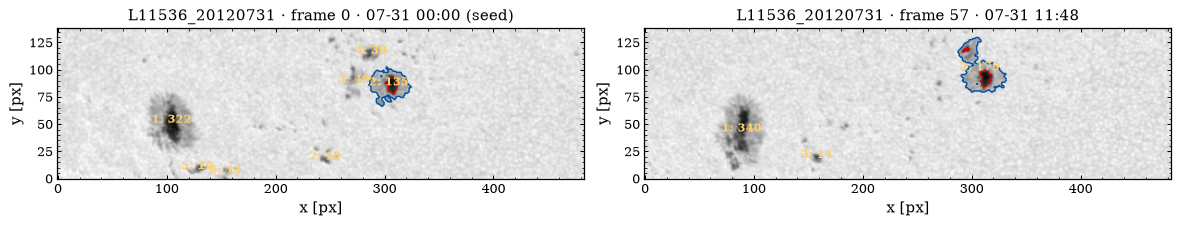

Löptien: área 124 Mm², θ = 34°


,x,y,n_px,mu,area_Mm2,umbra_Mm2
1,104.5,51.3,1721,0.7,322.0,50.3
2,304.0,85.6,788,0.8,134.7,19.2
3,272.0,88.2,283,0.8,48.8,0.0
4,287.7,114.7,178,0.8,30.3,0.8
5,128.2,8.8,99,0.7,18.7,0.0
6,154.1,4.7,67,0.7,12.5,0.0
7,245.4,17.5,58,0.8,10.4,0.0


C12526 [seed=largest]: 217 frames, mancha de 6157 px (mediana), 0 cambio(s) de mancha en el seguimiento


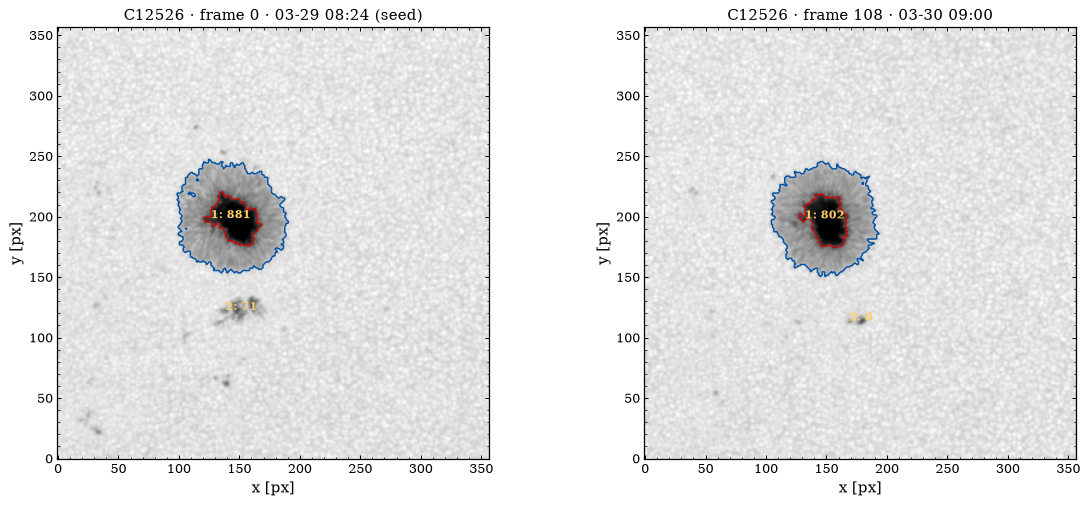

,x,y,n_px,mu,area_Mm2,umbra_Mm2
1,142.9,198.8,6378,1.0,880.6,158.1
2,151.7,122.9,513,1.0,70.6,0.4


C12574 [seed=leader]: 224 frames, mancha de 1705 px (mediana), 0 cambio(s) de mancha en el seguimiento


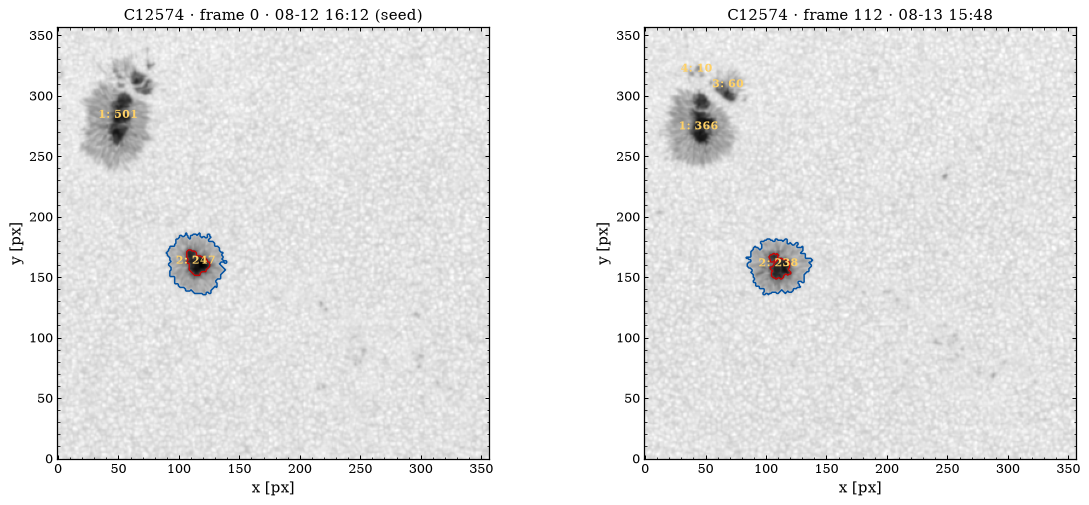

,x,y,n_px,mu,area_Mm2,umbra_Mm2
1,49.8,281.7,3506,1.0,501.0,61.3
2,114.0,161.1,1746,1.0,247.4,36.3


C12600 [seed=largest]: 228 frames, mancha de 3212 px (mediana), 0 cambio(s) de mancha en el seguimiento


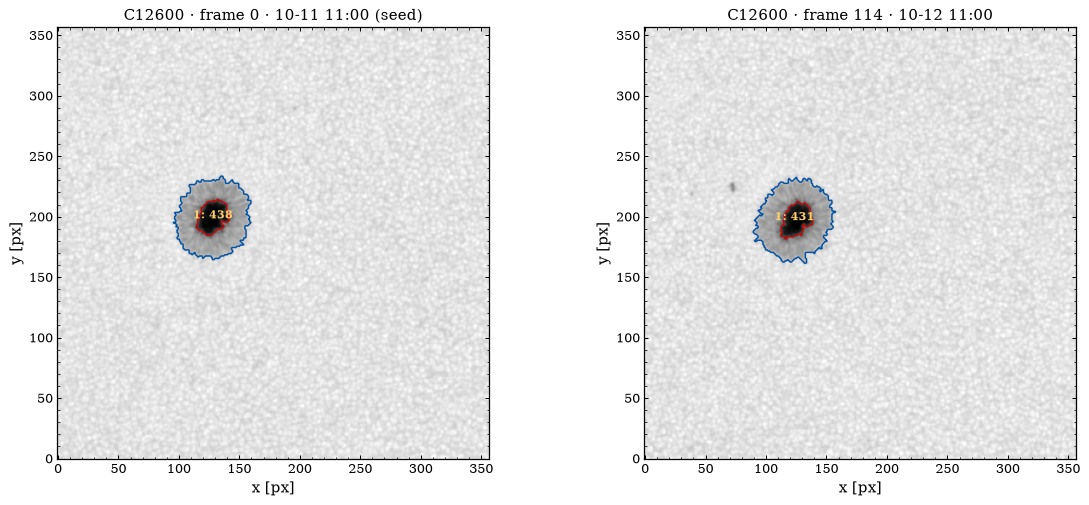

,x,y,n_px,mu,area_Mm2,umbra_Mm2
1,128.2,198.6,3171,1.0,438.5,75.5


C12664 [seed=largest]: 226 frames, mancha de 1799 px (mediana), 0 cambio(s) de mancha en el seguimiento


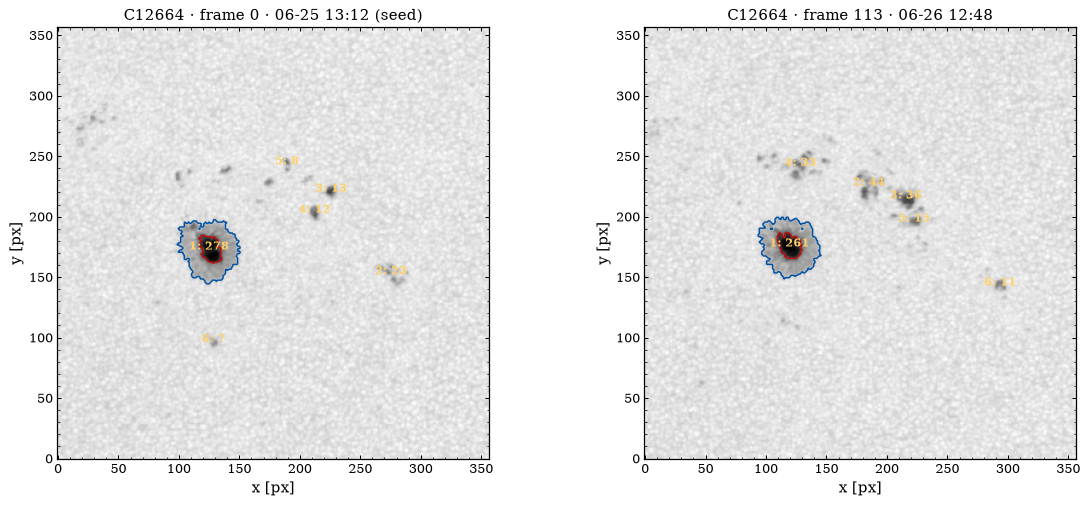

,x,y,n_px,mu,area_Mm2,umbra_Mm2
1,124.9,172.8,1867,0.9,277.9,43.9
2,275.5,152.5,157,1.0,22.8,0.0
3,225.9,220.7,89,0.9,13.2,1.6
4,212.4,203.4,84,0.9,12.4,0.0
5,189.5,243.2,51,0.9,7.6,0.0
6,128.7,96.2,50,0.9,7.4,0.0


C12670 [seed=largest]: 230 frames, mancha de 4404 px (mediana), 0 cambio(s) de mancha en el seguimiento


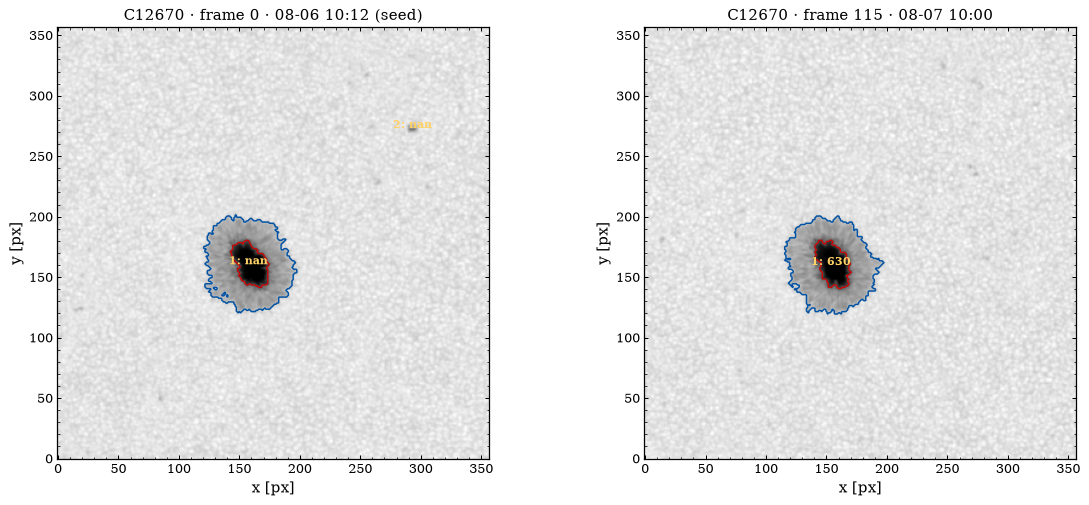

,x,y,n_px,mu,area_Mm2,umbra_Mm2
1,157.4,160.6,4455,NaN,NaN,NaN
2,293.2,273.3,53,NaN,NaN,NaN


In [3]:
if PREVIEW:
    for s in SPOTS:
        det = analysis.detect_spot(s)
        fig, tables = report.detection_figure(s, det)
        plt.show()
        if s['kind'] == 'loptien':
            print(f"Löptien: área {s['area']} Mm², θ = {s['theta']}°")
        display(tables[0][['x', 'y', 'n_px', 'mu', 'area_Mm2', 'umbra_Mm2']].round(1))

## 2. Análisis completo

In [4]:
results = {}
if RUN_ANALYSIS:
    for s in SPOTS:
        try:
            results[s['id']] = analysis.analyse_spot(s)
        except Exception as exc:
            print(f"{s['id']}: no se pudo analizar — {exc!r}")

L11106_20100916 [seed=largest]: 111 frames, mancha de 1195 px (mediana), 0 cambio(s) de mancha en el seguimiento
L11117_20101027 [seed=(250, 300)]: 114 frames, mancha de 1572 px (mediana), 0 cambio(s) de mancha en el seguimiento
L11117_20101028 [seed=(225, 270)]: 102 frames, mancha de 1406 px (mediana), 0 cambio(s) de mancha en el seguimiento
L11363_20111206 [seed=largest]: 107 frames, mancha de 7923 px (mediana), 0 cambio(s) de mancha en el seguimiento
L11536_20120731 [seed=(320, 80)]: 115 frames, mancha de 798 px (mediana), 0 cambio(s) de mancha en el seguimiento
C12526 [seed=largest]: 217 frames, mancha de 6157 px (mediana), 0 cambio(s) de mancha en el seguimiento
C12574 [seed=leader]: 224 frames, mancha de 1705 px (mediana), 0 cambio(s) de mancha en el seguimiento
C12600 [seed=largest]: 228 frames, mancha de 3212 px (mediana), 0 cambio(s) de mancha en el seguimiento
C12664 [seed=largest]: 226 frames, mancha de 1799 px (mediana), 0 cambio(s) de mancha en el seguimiento
C12670 [seed=

## Cómo se calcula el área (y dónde entra μ)

Un píxel HPC de HMI cubre siempre 0.5″ × 0.5″ en el **plano del cielo**. Lejos del centro del disco la superficie del Sol está inclinada, así que ese píxel cubre más superficie real: la mancha se ve acortada por un factor $\mu=\cos\theta$. El área real es

$$A_{\rm sol} \approx \frac{N_{\rm px}\,A_{\rm px}}{\mu}.$$

Aquí no se divide por μ a mano. La máscara se **reproyecta a la malla CEA de SHARP**, que es de áreas iguales sobre la esfera: cada píxel CEA mide $(\Delta\phi)(\Delta\sin\lambda)R_\odot^2$ esté donde esté. Contar píxeles CEA ya da el área sobre la superficie solar, con la corrección por μ de cada píxel incluida (también la variación de μ dentro de la mancha).

Comprobado con los datos: $N_{\rm px}A_{\rm px}/\mu$ y el área CEA difieren < 1 % (L11536 con μ = 0.78: 334 contra 332 Mm²).

`umbra_area_Mm2` y `penumbra_area_Mm2` vienen de la malla CEA; `umbra_px` y `penumbra_px` son píxeles HPC **sin** desproyectar.

## Campo en la umbra: media, máximo y perfil suavizado

Por frame, para $|B_{LOS}|$ (magnetograma) y para $|\mathbf B|$ y $|B_z|$ (SHARP), se guardan tres estadísticas:
- `<campo>`: la media en la umbra.
- `<campo>_max`: el máximo de un solo píxel. Es ruidoso y queda sesgado hacia arriba.
- `<campo>_max_s`: el máximo del mapa suavizado con una gaussiana de σ = `config.MAX_FIELD_SIGMA_PX` px. Es el pico a escala de ~1″ y es el análogo de $B_0$ en el ajuste $B_z(r)=B_0e^{-r^2/R^2}$.

Cada una tiene además su **perfil temporal suavizado** `<...>_ts`: una mediana móvil de `config.TIME_SMOOTH_FRAMES` frames, que ignora frames sueltos malos sin repartir el salto entre sus vecinos.


## Calidad del seguimiento

Hay que revisar dos columnas de `select_spot_cluster`:
- `switched`: el seguimiento perdió la mancha y la volvió a elegir. Hay que ver en qué frame pasó.
- `fraction`: qué parte de la huella oscura de la caja es esta mancha.

In [5]:
pd.DataFrame({sid: dict(frames=len(m), switched=int(m['switched'].sum()),
                        fraction_min=m['fraction'].min(), umbra_px_min=m['umbra_px'].min(),
                        umbra_px_med=m['umbra_px'].median())
              for sid, (m, _) in results.items()}).T

,frames,switched,fraction_min,umbra_px_min,umbra_px_med
L11106_20100916,111.0,0.0,0.372928,193.0,211.0
L11117_20101027,114.0,0.0,0.101527,139.0,164.0
L11117_20101028,102.0,0.0,0.087234,160.0,171.0
L11363_20111206,107.0,0.0,0.662529,1134.0,1175.0
L11536_20120731,115.0,0.0,0.208886,104.0,119.0
C12526,217.0,0.0,0.895032,1063.0,1129.0
C12574,224.0,0.0,0.321896,206.0,244.0
C12600,228.0,0.0,0.984705,483.0,536.0
C12664,226.0,0.0,0.519926,261.0,298.5
C12670,230.0,0.0,0.969325,734.0,792.0


## Índice de la muestra y comparación con Löptien

`muestra_index.csv` tiene una fila por mancha, con la media y la desviación estándar de las métricas por frame en su ventana. Para las de Löptien también trae sus columnas: θ, área, ⟨B⟩, $z_{div}$, $z_{press}$.

Diferencias esperables con Hinode, según el *Ojo* de S4 en `description.md`:
- **⟨B⟩ umbral**: HMI usa otra línea, otra resolución y otra inversión (Milne–Eddington).
- **Área**: la columna de Löptien se parece al área **total** de la mancha (umbra + penumbra), no a la de la umbra; y sus umbrales no son los de aquí.
- **θ**: aquí es el promedio del día, y Löptien da un solo barrido.

In [6]:
index = analysis.summarise()
index

,id,noaa,kind,harpnum,t_start,t_end,n_frames,n_switched,mu,mu_std,...,Bz_umbra_std,Bz_umbra_max,Bz_umbra_max_std,Bz_umbra_max_s,Bz_umbra_max_s_std,theta_loptien,area_loptien,B_loptien,z_div,z_press
0,L11106_20100916,11106,loptien,175,2010-09-16 00:12:00,2010-09-16 23:48:00,111,0,0.888290,0.005107,...,30.095023,2523.732875,47.811455,2326.634738,27.741356,27.0,195.0,2349.0,636.0,381.0
1,L11117_20101027,11117,loptien,226,2010-10-27 00:00:00,2010-10-27 23:48:00,114,0,0.873291,0.023173,...,46.302501,2207.916834,40.663066,1997.060461,48.064828,25.0,522.0,2093.0,561.0,291.0
2,L11117_20101028,11117,loptien,226,2010-10-28 00:00:00,2010-10-28 23:48:00,102,0,0.775222,0.035314,...,43.053717,2349.642549,50.272747,2144.520518,35.872854,35.0,223.0,2090.0,625.0,313.0
3,L11363_20111206,11363,loptien,1124,2011-12-06 00:00:00,2011-12-06 23:48:00,107,0,0.884607,0.016284,...,28.926968,2682.343926,34.680225,2480.708942,25.870351,25.0,1268.0,2287.0,524.0,326.0
4,L11536_20120731,11536,loptien,1879,2012-07-31 00:00:00,2012-07-31 23:48:00,115,0,0.842385,0.018744,...,47.311212,2306.039479,45.354367,2075.574859,42.367055,34.0,124.0,2181.0,577.0,346.0
5,C12526,12526,catalog,6454,2016-03-29 08:24:00,2016-03-31 08:12:00,217,0,0.989688,0.008292,...,23.596764,2931.523962,64.409874,2773.854523,60.499508,NaN,NaN,NaN,NaN,NaN
6,C12574,12574,catalog,6699,2016-08-12 16:12:00,2016-08-14 15:36:00,224,0,0.989852,0.007879,...,35.175209,2528.271521,63.352042,2255.348248,37.885402,NaN,NaN,NaN,NaN,NaN
7,C12600,12600,catalog,6798,2016-10-11 11:00:00,2016-10-13 10:48:00,228,0,0.986431,0.008327,...,17.625873,2724.804912,79.800279,2510.253690,49.032543,NaN,NaN,NaN,NaN,NaN
8,C12664,12664,catalog,7058,2017-06-25 13:12:00,2017-06-27 13:00:00,226,0,0.953960,0.009107,...,32.282194,2623.138585,48.136674,2406.077485,34.673294,NaN,NaN,NaN,NaN,NaN
9,C12670,12670,catalog,7100,2017-08-06 10:12:00,2017-08-08 10:00:00,230,0,0.966056,0.008908,...,25.070486,2925.788566,97.041527,2748.663463,71.103989,NaN,NaN,NaN,NaN,NaN


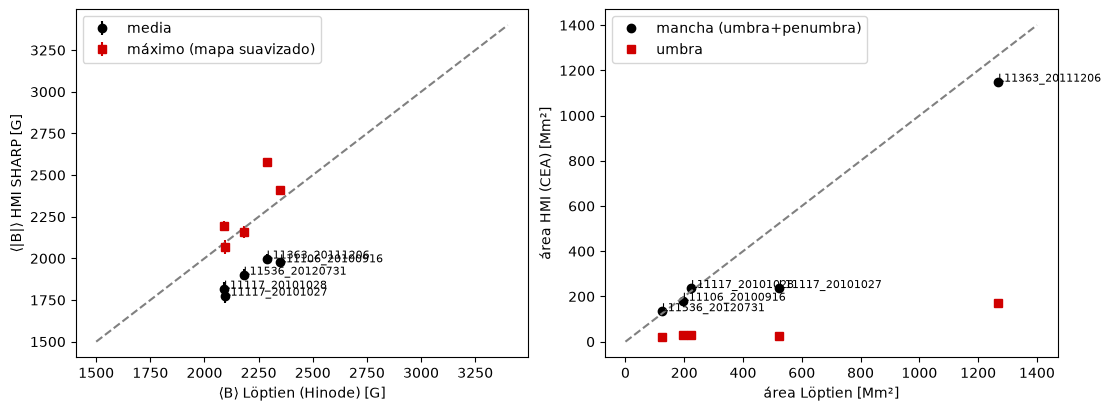

In [7]:
lop = index[index['kind'] == 'loptien']
if len(lop):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
    axes[0].errorbar(lop['B_loptien'], lop['B_umbra'], yerr=lop['B_umbra_std'], fmt='o', color='k', label='media')
    axes[0].errorbar(lop['B_loptien'], lop['B_umbra_max_s'], yerr=lop['B_umbra_max_s_std'], fmt='s', color='#D00000',
                     label='máximo (mapa suavizado)')
    axes[0].legend()
    lim = [1500, 3400]; axes[0].plot(lim, lim, '--', color='0.5')
    axes[0].set_xlabel('⟨B⟩ Löptien (Hinode) [G]'); axes[0].set_ylabel('⟨|B|⟩ HMI SHARP [G]')
    lop = lop.assign(spot_area=lop['umbra_area_Mm2'] + lop['penumbra_area_Mm2'])
    axes[1].plot(lop['area_loptien'], lop['spot_area'], 'o', color='k', label='mancha (umbra+penumbra)')
    axes[1].plot(lop['area_loptien'], lop['umbra_area_Mm2'], 's', color='#D00000', label='umbra')
    axes[1].plot([0, 1400], [0, 1400], '--', color='0.5'); axes[1].legend()
    axes[1].set_xlabel('área Löptien [Mm²]'); axes[1].set_ylabel('área HMI (CEA) [Mm²]')
    for _, r in lop.iterrows():
        axes[0].annotate(r['id'], (r['B_loptien'], r['B_umbra']), fontsize=8)
        axes[1].annotate(r['id'], (r['area_loptien'], r['spot_area']), fontsize=8)
    plt.show()

## Cómo leer los datos procesados con sunpy

Ejemplo con el frame central de la primera mancha. Muestra la máscara HPC con coordenadas helioproyectivas y $B_z$ CEA con la máscara reproyectada.

helioprojective | heliographic_carrington
HPC -> <SkyCoord (HeliographicStonyhurst: obstime=2010-09-16T12:47:28.668, rsun=696000.0 km): (lon, lat, radius) in (deg, deg, m)
    (-3.56291164, -19.62479615, 6.96e+08)>
CEA -> <SkyCoord (HeliographicStonyhurst: obstime=2010-09-16T12:47:28.668, rsun=696000.0 km): (lon, lat, radius) in (deg, deg, km)
    (-3.56279896, -19.6273045, 696000.)>


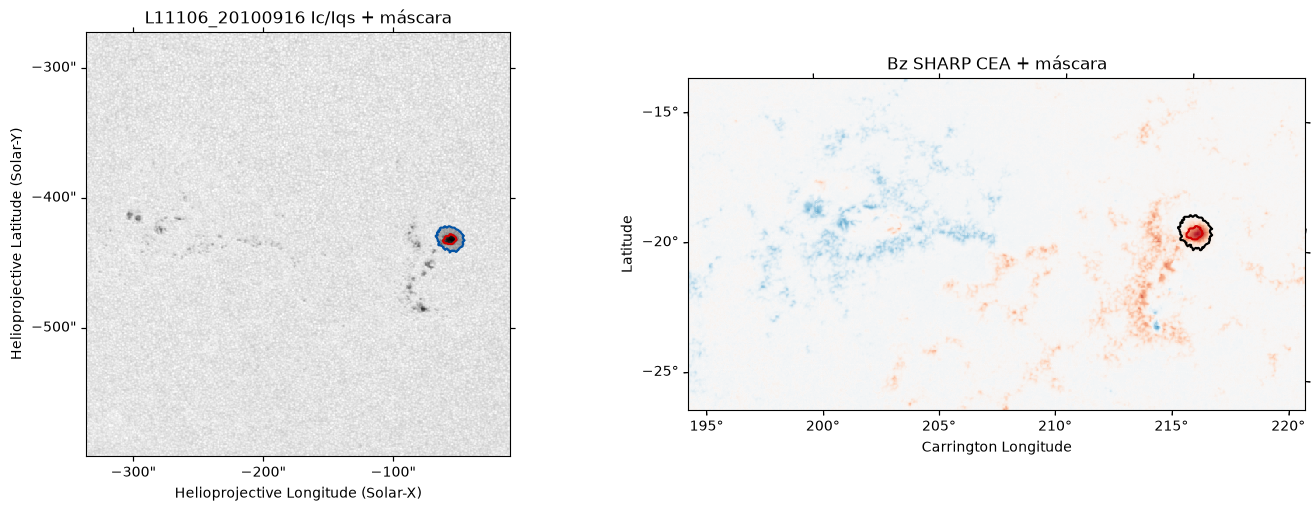

In [8]:
import sunpy.map
import astropy.units as u
from matplotlib.colors import Normalize
from sunpy.coordinates import frames

sid = next(iter(results)) if results else SPOTS[0]['id']
if sid not in results:
    results[sid] = (pd.read_csv(config.PROCESSED_DIR / sid / 'frames_metrics.csv', index_col='time', parse_dates=['time']), None)
t = results[sid][0].index[len(results[sid][0]) // 2]
stamp = f'{t:%Y%m%d_%H%M%S}'
d = config.PROCESSED_DIR / sid
ic = sunpy.map.Map(d / 'hpc' / 'continuum' / f'continuum_{stamp}.fits')
mask = sunpy.map.Map(d / 'hpc' / 'mask' / f'mask_{stamp}.fits')
bz = sunpy.map.Map(d / 'cea' / 'Bz' / f'Bz_{stamp}.fits')
mask_cea = sunpy.map.Map(d / 'cea' / 'mask' / f'mask_{stamp}.fits')
print(ic.coordinate_frame.name, '|', bz.coordinate_frame.name)

# Centroide de la umbra en las dos mallas: tienen que caer en el mismo punto del Sol.
y, x = np.argwhere(mask.data == 1).mean(axis=0)
c_hpc = mask.pixel_to_world(x * u.pix, y * u.pix)
y, x = np.argwhere(mask_cea.data == 1).mean(axis=0)
c_cea = mask_cea.pixel_to_world(x * u.pix, y * u.pix)
print('HPC ->', c_hpc.transform_to(frames.HeliographicStonyhurst))
print('CEA ->', c_cea.transform_to(frames.HeliographicStonyhurst))

fig = plt.figure(figsize=(14, 5), layout='constrained')
ax = fig.add_subplot(1, 2, 1, projection=ic)
ic.plot(axes=ax, cmap='gray', norm=Normalize(0.2, 1.1), title=f'{sid} Ic/Iqs + máscara')
ax.contour(mask.data > 0, levels=[0.5], colors='#0353A4')   # borde de la mancha
ax.contour(mask.data == 1, levels=[0.5], colors='#D00000')  # borde de la umbra
ax = fig.add_subplot(1, 2, 2, projection=bz)
bz.plot(axes=ax, cmap='RdBu_r', norm=Normalize(-3000, 3000), title='Bz SHARP CEA + máscara')
ax.contour(mask_cea.data > 0, levels=[0.5], colors='k')
ax.contour(mask_cea.data == 1, levels=[0.5], colors='#D00000')
plt.show()

## Resumen HTML

`data/processed/sumary.html` es un solo archivo con todas las figuras incrustadas.

In [9]:
path = report.build_summary()
print(path)

/mnt/shared/Projects/wilson_depresion_electrodinamics/data/processed/sumary.html
